# 2. De quoi parle la recherche française en IA ? (NLP)

Corpus : résumés des 1 000 articles d'IA les plus cités depuis 2022, avec au moins un auteur affilié en France, comparés à ceux d'auteurs affiliés aux États-Unis (source : OpenAlex, voir `src/collecte_openalex.py`).

Méthodes reprises du cours (partie NLP) : tokenisation et lemmatisation avec spaCy, retrait des *stopwords*, fréquences, **nuages de mots**, loi de Zipf. On compare ensuite les deux corpus terme par terme, en calculant la part des articles qui mentionnent chaque terme dans chaque pays.

**Hypothèse.** La recherche française en IA est plus théorique et mathématique (optimisation, statistique, transport optimal) et plus tournée vers le multilinguisme ; la recherche américaine est davantage centrée sur le passage à l'échelle et les agents.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import FIGURES
from style import COULEURS_PAYS, appliquer_style
appliquer_style()
FIGURES.mkdir(exist_ok=True)
import spacy
from texte import nettoyer, frequences, comparer_presence, nuage
from nettoyage import charger_dernier

## 0. Le corpus

In [2]:
resumes = charger_dernier("openalex_resumes")
resumes = resumes.dropna(subset=["resume"])
resumes = resumes.loc[resumes["resume"].str.len() > 200]   # résumés tronqués ou vides
resumes["pays"] = resumes["pays"].map({"fr": "France", "us": "États-Unis"})
resumes["longueur"] = resumes["resume"].str.split().str.len()

resumes.groupby("pays").agg(articles=("id", "count"), mots_moyens=("longueur", "mean"),
                            mots_medians=("longueur", "median"), citations_medianes=("citations", "median")).round(0)

Lecture locale : data/raw/openalex_resumes_2026-11-22.csv


,articles,mots_moyens,mots_medians,citations_medianes
pays,,,,
France,997,180.0,175.0,62.0
États-Unis,995,174.0,179.0,508.0


### Documents hors sujet

En explorant le corpus, on constate que la catégorie « Artificial Intelligence » d'OpenAlex contient des articles d'**informatique quantique** (« Noisy intermediate-scale quantum algorithms », « Quantum computing with Qiskit »…), qui relèvent d'un autre domaine : la classification automatique d'OpenAlex n'est pas parfaite. Ces articles pèsent davantage dans le corpus français que dans l'américain et fausseraient la comparaison des vocabulaires.

On les retire sur la base de leur **titre**. Ce choix est rappelé dans le rapport ; passer `EXCLURE_HORS_SUJET = False` permet de vérifier son effet sur les résultats.

In [3]:
EXCLURE_HORS_SUJET = True
motif_hors_sujet = r"\bquantum\b"

hors_sujet = resumes["titre"].fillna("").str.contains(motif_hors_sujet, case=False)
print(resumes.assign(hors_sujet=hors_sujet).groupby("pays")["hors_sujet"].agg(["sum", "mean"])
      .rename(columns={"sum": "articles écartés", "mean": "part"}).round(3))
if EXCLURE_HORS_SUJET:
    resumes = resumes.loc[~hors_sujet].copy()

            articles écartés   part
pays                               
France                   108  0.108
États-Unis                43  0.043


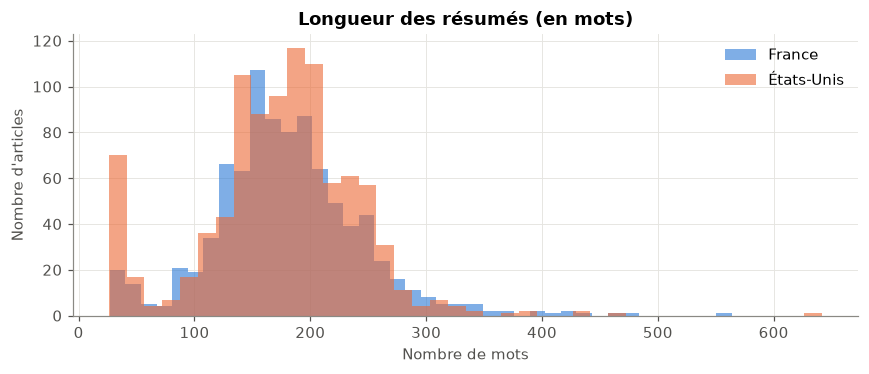

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for pays in ["France", "États-Unis"]:
    ax.hist(resumes.loc[resumes["pays"] == pays, "longueur"], bins=40, alpha=0.6,
            color=COULEURS_PAYS[pays], label=pays)
ax.set_title("Longueur des résumés (en mots)")
ax.set_xlabel("Nombre de mots"); ax.set_ylabel("Nombre d'articles")
ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "10_longueur_resumes.png")

**Interprétation.** Les deux corpus ont presque la même taille après le retrait des articles hors sujet (889 articles français et 952 américains) et des résumés de longueur comparable (environ 175 mots en médiane). Une différence de longueur aurait gonflé les fréquences brutes du corpus le plus long. C'est pour éviter ce biais que la section 4 compare des parts d'articles plutôt que des nombres d'occurrences. Le rapport final retire en plus les articles présents dans les deux classements et les notices bibliographiques : il porte sur 832 résumés français et 843 américains, et ses chiffres diffèrent donc légèrement de ceux de cette annexe.

## 1. Avant nettoyage : les mots les plus fréquents

Comme dans le cours avec *Le Comte de Monte-Cristo* : sans nettoyage, les mots outils dominent.

In [5]:
from collections import Counter
brut_compte = Counter(" ".join(resumes["resume"]).lower().split())
pd.DataFrame(brut_compte.most_common(15), columns=["mot", "occurrences"]).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
mot,the,and,of,to,a,in,we,for,that,on,with,is,this,as,by
occurrences,14529,10695,10419,7895,6669,5998,4567,3788,3353,3330,2747,2696,2604,2226,1784


## 2. Nettoyage avec spaCy

Lemmatisation, retrait des *stopwords* de spaCy, de la ponctuation et des nombres, plus une liste de **stopwords académiques** (« propose », « method », « result »…) présents dans tout résumé scientifique et sans contenu propre (voir `src/texte.py`). Ces mots apparaissent dans presque tous les résumés et masqueraient les différences entre les deux corpus.

In [6]:
nlp = spacy.load("en_core_web_sm")
resumes["tokens"] = nettoyer(resumes["resume"].tolist(), nlp)
freq = {p: frequences(resumes.loc[resumes["pays"] == p, "tokens"]) for p in ["France", "États-Unis"]}
pd.concat({p: f.head(15).set_index("rang")[["terme", "freq"]] for p, f in freq.items()}, axis=1)

France      États-Unis      
          terme freq      terme  freq
rang                                 
1          data  880        llm  1314
2      learning  683   language  1108
3          base  624       data   872
4      language  558   learning   649
5       dataset  459      human   536
6        system  444   training   524
7     algorithm  370     prompt   478
8     challenge  358       base   458
9       network  347    dataset   434
10        learn  338   research   414
11     research  336     system   406
12         time  327      train   390
13          llm  312  reasoning   368
14      machine  310       text   361
15      feature  302   generate   349

## 3. Nuages de mots

Dans un nuage de mots, **la taille d'un terme est proportionnelle à sa fréquence**. C'est une visualisation d'appel, pas de mesure : les tailles se comparent mal à l'œil. On l'accompagne donc toujours d'un graphique en barres.

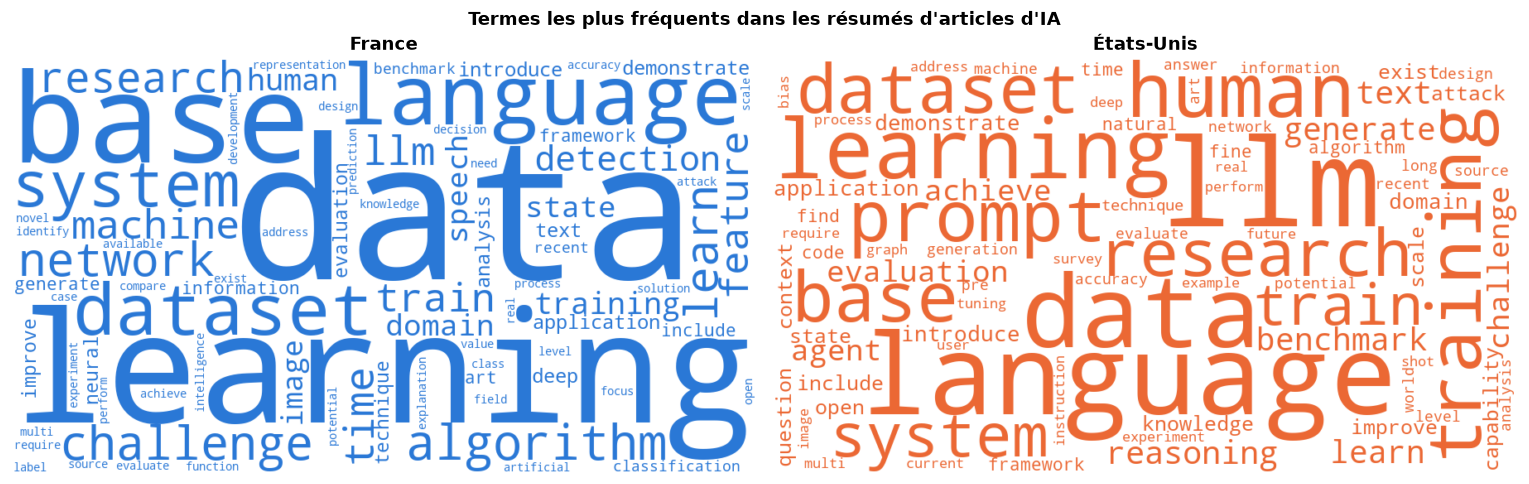

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, pays in zip(axes, ["France", "États-Unis"]):
    nuage(dict(zip(freq[pays]["terme"], freq[pays]["freq"])), ax, pays, couleur=COULEURS_PAYS[pays])
fig.suptitle("Termes les plus fréquents dans les résumés d'articles d'IA", fontweight="bold")
fig.tight_layout(); fig.savefig(FIGURES / "11_nuages_frequences.png")

**Interprétation.** Les deux nuages se ressemblent beaucoup, car les mots les plus fréquents (*data*, *learning*, *language*, *dataset*) sont ceux de toute la discipline. On voit quand même que *llm* domine le nuage américain alors qu'il est beaucoup plus petit dans le nuage français. Pour voir ce qui distingue vraiment chaque pays, il faut comparer les deux corpus terme par terme (section 4).

## 4. Les termes associés à la France

Pour chaque terme, on calcule la part des articles qui le mentionnent en France et aux États-Unis, puis le rapport entre les deux : un rapport de 3 veut dire que le terme apparaît, proportionnellement, dans 3 fois plus d'articles français qu'américains. On compte des articles plutôt que des occurrences, pour qu'un terme répété dans un seul résumé ne pèse pas trop, et on ne garde que les termes présents dans au moins 20 articles.

Dans les nuages de mots de cette section, **la taille d'un terme est ce rapport** : elle mesure à quel point il est plus fréquent dans un corpus que dans l'autre, et non plus sa simple fréquence.

In [8]:
comparaison = comparer_presence(resumes.loc[resumes["pays"] == "France", "tokens"].tolist(),
                                resumes.loc[resumes["pays"] == "États-Unis", "tokens"].tolist())
cote_france = comparaison.head(30)
cote_usa = comparaison.tail(30).iloc[::-1]
print(f"{len(comparaison)} termes comparés")
comparaison.head(10).round(2)

1315 termes comparés


,terme,articles_a,articles_b,part_a,part_b,rapport
0,french,20.0,0.0,0.02,0.00,22.49
1,xai,38.0,3.0,0.04,0.00,10.44
2,european,24.0,3.0,0.03,0.00,6.69
3,voice,23.0,3.0,0.03,0.00,6.42
4,computing,32.0,5.0,0.04,0.01,5.89
5,behaviour,20.0,3.0,0.02,0.00,5.62
6,interpretation,21.0,4.0,0.02,0.00,4.71
7,explainable,49.0,12.0,0.06,0.01,4.12
8,aid,22.0,5.0,0.02,0.01,4.10
9,statistic,21.0,5.0,0.02,0.01,3.93


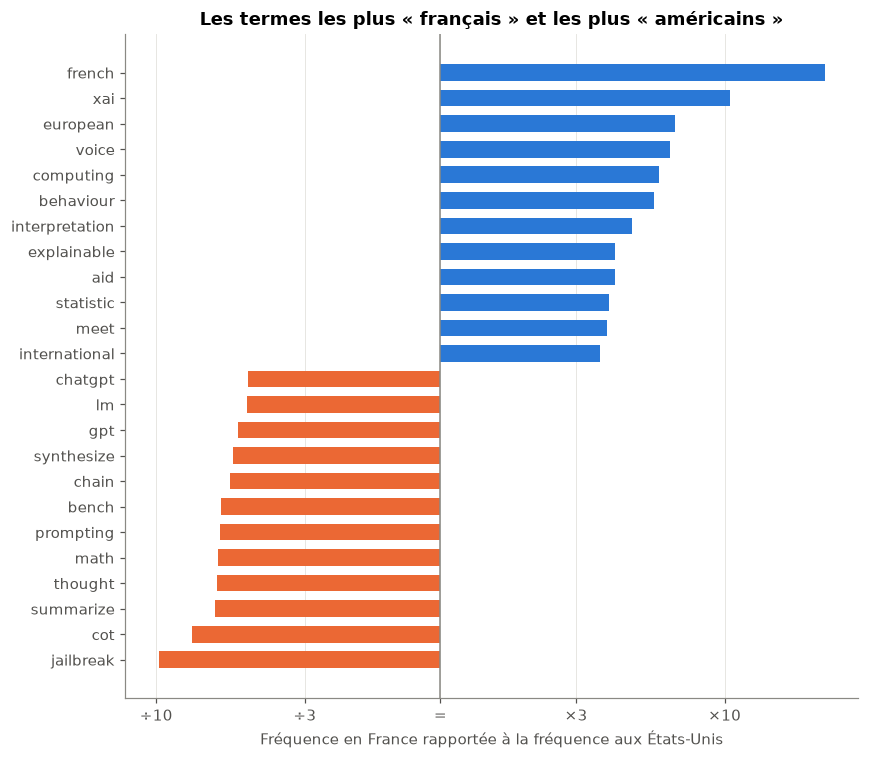

In [9]:
from graphiques import barres_rapport

barres_rapport(pd.concat([cote_france.head(12), cote_usa.head(12)]),
               "Les termes les plus « français » et les plus « américains »",
               fichier=FIGURES / "12_termes_distinctifs.png")
plt.show()

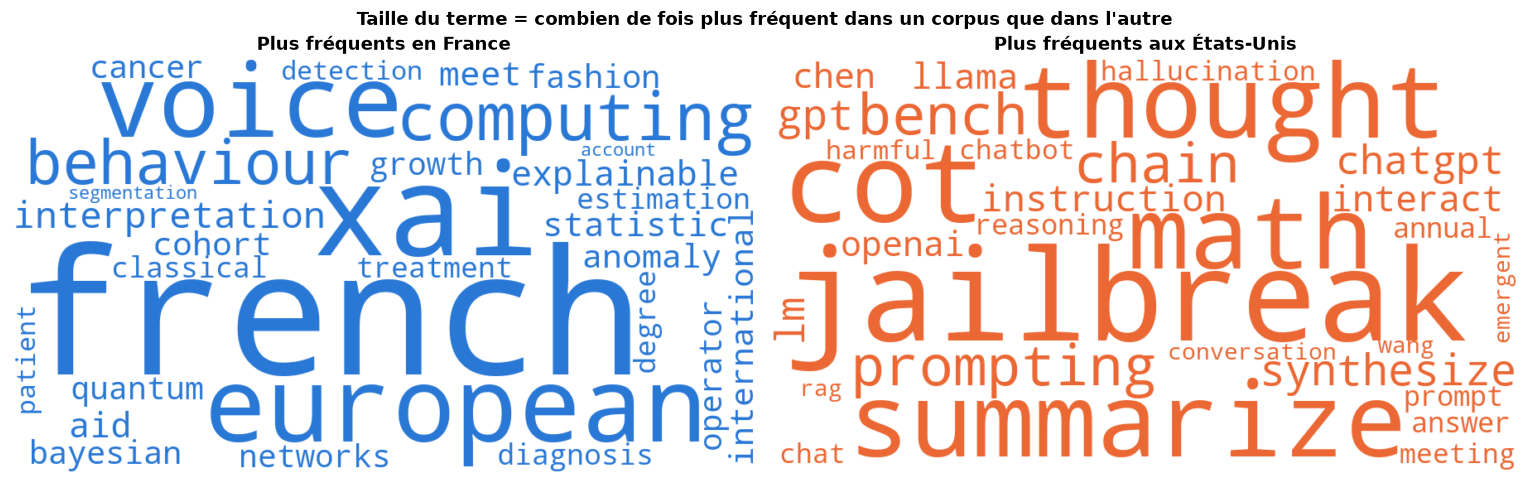

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
nuage(dict(zip(cote_france["terme"], cote_france["rapport"])), axes[0], "Plus fréquents en France", COULEURS_PAYS["France"])
nuage(dict(zip(cote_usa["terme"], 1 / cote_usa["rapport"])), axes[1], "Plus fréquents aux États-Unis", COULEURS_PAYS["États-Unis"])
fig.suptitle("Taille du terme = combien de fois plus fréquent dans un corpus que dans l'autre", fontweight="bold")
fig.tight_layout(); fig.savefig(FIGURES / "13_nuages_distinctifs.png")

**Interprétation.** Du côté français ressortent l'IA explicable (*xai*, *explainable*, *interpretation*, 4 à 10 fois plus fréquents qu'aux États-Unis), la voix (*voice*), les statistiques (*statistic*) et une dimension européenne (*european*, *french*). Du côté américain, ce sont les grands modèles de langage qui dominent, avec *chatgpt*, *gpt*, *prompting*, le raisonnement étape par étape et le contournement des protections (*jailbreak*). L'hypothèse de départ se vérifie en bonne partie. Les termes *theoretical* (×2,4), *statistic* (×3,9) et *multilingual* (×1,8) sont plus fréquents dans les articles français, alors que *agent* et *scale* sont environ 1,6 fois plus fréquents dans les articles américains. En revanche, *optimization* apparaît autant des deux côtés, et le transport optimal est trop rare pour être mesuré. Surtout, la France publie peu sur les grands modèles de langage, c'est-à-dire sur le domaine où se joue la course aux modèles (notebook 1).

## 5. La loi de Zipf

Le cours vérifie la loi de Zipf sur un roman : la fréquence d'un mot est à peu près inversement proportionnelle à son rang. Tient-elle aussi pour un vocabulaire scientifique spécialisé ? On l'estime par une régression de Poisson, comme dans le cours.

,pays,pente,vocabulaire
0,France,-0.797,8733
1,États-Unis,-0.821,8113


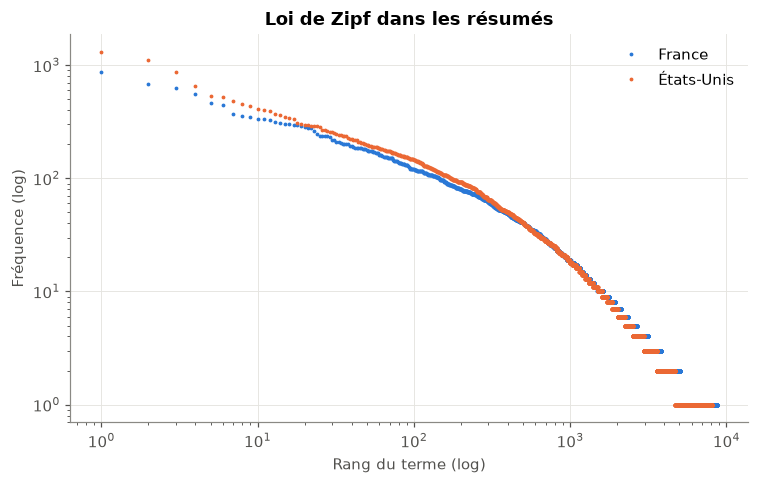

In [11]:
import statsmodels.api as sm

lignes = []
fig, ax = plt.subplots(figsize=(7, 4.5))
for pays, f in freq.items():
    ax.loglog(f["rang"], f["freq"], ".", markersize=3, color=COULEURS_PAYS[pays], label=pays)
    exog = sm.add_constant(np.log(f["rang"].astype(float)))
    glm = sm.GLM(f["freq"].astype(float), exog, family=sm.families.Poisson()).fit()
    lignes.append({"pays": pays, "pente": round(glm.params.iloc[1], 3), "vocabulaire": len(f)})
ax.set_xlabel("Rang du terme (log)"); ax.set_ylabel("Fréquence (log)")
ax.set_title("Loi de Zipf dans les résumés")
ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "14_zipf.png")
pd.DataFrame(lignes)

**Interprétation.** Les pentes sont de −0,80 pour la France et −0,82 pour les États-Unis, assez proches de −1 : la décroissance est compatible avec une loi de Zipf, même pour un vocabulaire scientifique spécialisé. La pente française est légèrement plus faible et le vocabulaire français un peu plus riche (8 733 mots différents contre 8 113). Le vocabulaire français est donc un peu moins concentré sur quelques mots, ce qui va dans le même sens que la section 4, où les articles américains se concentrent sur les grands modèles de langage.

## 6. Évolution de quelques termes dans le temps

Part des résumés mentionnant un terme, par année et par pays. Nous suivons deux termes typiquement français (*explainable*, *voice*) et deux termes typiquement américains (*llm*, *prompt*), choisis à partir des résultats de la section 4.

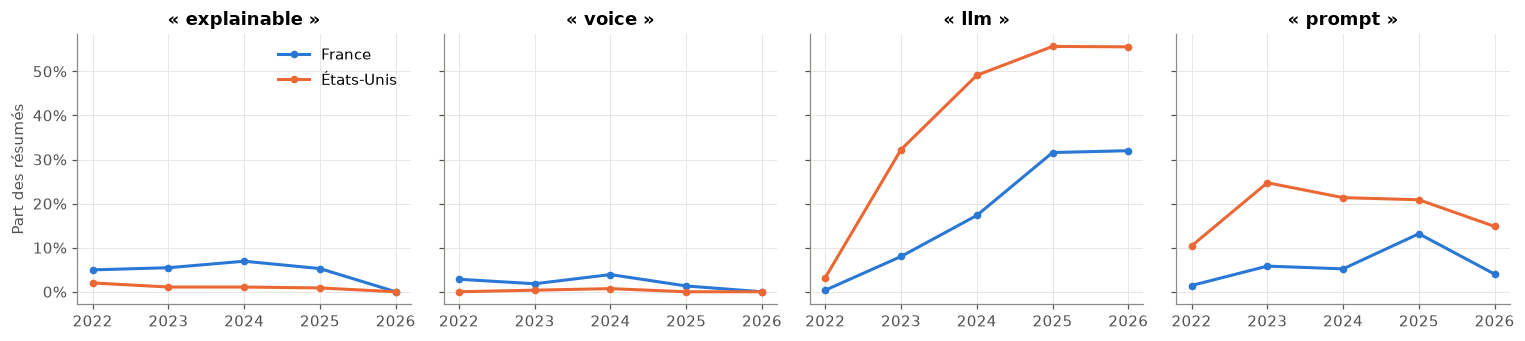

In [12]:
termes_suivis = ["explainable", "voice", "llm", "prompt"]

resumes["texte_nettoye"] = resumes["tokens"].str.join(" ")
suivi = pd.concat({t: resumes.assign(present=resumes["texte_nettoye"].str.contains(rf"\b{t}\b"))
                          .groupby(["annee", "pays"])["present"].mean()
                   for t in termes_suivis}, names=["terme"]).unstack("pays")

fig, axes = plt.subplots(1, len(termes_suivis), figsize=(14, 3.2), sharey=True)
for ax, t in zip(axes, termes_suivis):
    for pays in ["France", "États-Unis"]:
        ax.plot(suivi.loc[t].index, suivi.loc[t][pays], marker="o", markersize=4,
                color=COULEURS_PAYS[pays], label=pays)
    ax.set_title(f"« {t} »")
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
axes[0].set_ylabel("Part des résumés")
axes[0].legend()
fig.tight_layout(); fig.savefig(FIGURES / "15_termes_dans_le_temps.png")

**Interprétation.** Le terme *llm* explose dans les deux pays après la sortie de ChatGPT, mais beaucoup plus vite aux États-Unis, où il apparaît dans plus de la moitié des résumés à partir de 2025, contre environ un tiers en France. La France suit donc la vague des grands modèles de langage avec du retard. *Prompt* reste nettement plus américain sur toute la période. À l'inverse, *explainable* et *voice* sont plus fréquents en France chaque année jusqu'en 2025. Les valeurs de 2026 reposent sur peu d'articles, car les articles récents ont encore peu de citations et entrent moins dans notre échantillon.

## Limites

- **Affiliation, pas nationalité** : un article est « français » s'il a au moins un auteur dans une institution française. Les co-signatures internationales sont comptées des deux côtés.
- **Échantillon** : les articles les plus cités, pas l'ensemble de la production. Les articles français retenus sont d'ailleurs beaucoup moins cités que les américains (62 citations en médiane contre 508).
- **Langue** : les résumés sont presque tous en anglais ; on ne mesure pas la recherche publiée en français.
- **Stopwords académiques** : la liste est un choix qui influence les résultats.